# Milestone 2 — Audio-based similarity validation (FMA-small)

**Purpose:** Strengthen the original-feature / PCA / autoencoder comparison by checking whether retrieved songs share measurable characteristics **extracted from their actual MP3 recordings**.

This notebook **does not retrain your three models**. It reuses `results/milestone2/retrieval_results.csv` from `05_milestone2.ipynb`, extracts audio descriptors, and compares retrieved pairs with random cross-genre pairs.

**Inputs:** FMA-small MP3 files (downloaded directly in Colab or attached as a Kaggle dataset), processed split NPZ files, metadata CSV, and the existing retrieval CSV. **Outputs:** cached audio descriptors (`.npz` + `.csv`), comparison tables, plots, and listening examples.

> This is an *audio-based evaluation*, not yet a new spectrogram autoencoder. It is the recommended first stage before deciding whether another model is justified.


## 1. Setup — Colab or local

In [1]:
# Works in Google Colab, Kaggle Notebooks, or locally. No Google Drive needed.
import sys, subprocess, importlib.util
for pkg, module in [('librosa>=0.10.2','librosa'), ('soundfile','soundfile'), ('tqdm','tqdm')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

from pathlib import Path
import os, zipfile, warnings, shutil, hashlib
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Audio

SEED = 42
rng = np.random.default_rng(SEED)
REPO_URL = 'https://github.com/samiyaalizaidi/music-similarity-representation-learning.git'
REPO_NAME = 'music-similarity-representation-learning'
IS_KAGGLE = Path('/kaggle/input').is_dir()
IS_COLAB = 'google.colab' in sys.modules

cwd = Path.cwd().resolve()
existing_repo = next((p for p in (cwd, *cwd.parents) if (p / 'data' / 'processed').exists()), None)
if existing_repo is not None:
    PROJECT_ROOT = existing_repo
else:
    workspace = Path('/kaggle/working') if IS_KAGGLE else Path('/content') if IS_COLAB else cwd
    PROJECT_ROOT = workspace / REPO_NAME
    if not PROJECT_ROOT.exists():
        subprocess.run(['git','clone',REPO_URL,str(PROJECT_ROOT)], check=True)

DATA_DIR = PROJECT_ROOT / 'data' / 'processed'
PREVIOUS_RESULTS = PROJECT_ROOT / 'results' / 'milestone2' / 'retrieval_results.csv'
OUT_DIR = PROJECT_ROOT / 'results' / 'audio_validation'
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Environment:', 'Kaggle' if IS_KAGGLE else 'Colab' if IS_COLAB else 'Local')
print('Repository:', PROJECT_ROOT)
print('Retrieval CSV:', PREVIOUS_RESULTS, 'exists:', PREVIOUS_RESULTS.exists())
print('If processed files or retrieval CSV are not committed to GitHub, upload them into the matching repository paths.')


Cloning into '/kaggle/working/music-similarity-representation-learning'...


Environment: Kaggle
Repository: /kaggle/working/music-similarity-representation-learning
Retrieval CSV: /kaggle/working/music-similarity-representation-learning/results/milestone2/retrieval_results.csv exists: True
If processed files or retrieval CSV are not committed to GitHub, upload them into the matching repository paths.


## 2. Get FMA-small audio — Kaggle or direct official download

**Kaggle (recommended when audio is already hosted there):** In a Kaggle Notebook, select **Add Input** and attach an FMA-small dataset containing the **original MP3 recordings**. The code searches `/kaggle/input` for the standard `000/000002.mp3` layout. No additional download is required.

**Colab:** Set `AUDIO_SOURCE = "official"` to download `fma_small.zip` directly from the [official FMA archive](https://os.unil.cloud.switch.ch/fma/fma_small.zip) and extract it into the temporary Colab filesystem. The archive is approximately **7.2 GiB** and extraction needs additional disk space. Colab sessions are temporary, so downloads may need repeating.

**Local:** Set `AUDIO_ROOT` manually if the recordings already exist on disk.

The notebook uses FMA **track IDs**, so avoid datasets that rename or transform the audio without preserving original IDs. Precomputed spectrogram datasets are not suitable for this MP3-based analysis.


In [2]:
# Choose 'auto' (Kaggle/local search), 'official' (download + extract), or 'existing'.
AUDIO_SOURCE = 'auto'
AUDIO_ROOT = None  # Optional explicit path to the folder containing 000/, 001/, ...
OFFICIAL_URL = 'https://os.unil.cloud.switch.ch/fma/fma_small.zip'
OFFICIAL_SHA1 = 'ade154f733639d52e35e32f5593efe5be76c6d70'

def looks_like_fma_root(folder):
    folder = Path(folder)
    return folder.is_dir() and bool(list(folder.glob('[0-9][0-9][0-9]/*.mp3')))

def locate_audio_root():
    locations = [PROJECT_ROOT / 'data' / 'fma_small', Path('/content/fma_small')]
    if IS_KAGGLE:
        locations += [p for p in Path('/kaggle/input').glob('**/fma_small') if p.is_dir()]
        # Kaggle repacks often omit the fma_small parent folder.
        locations += [d.parent for d in Path('/kaggle/input').glob('**/000') if d.is_dir()]
    return next((p for p in locations if looks_like_fma_root(p)), None)

if AUDIO_ROOT is not None:
    AUDIO_ROOT = Path(AUDIO_ROOT)
elif AUDIO_SOURCE in ('auto','existing'):
    AUDIO_ROOT = locate_audio_root()

if AUDIO_ROOT is None and AUDIO_SOURCE == 'official':
    import urllib.request
    workspace = Path('/kaggle/working') if IS_KAGGLE else Path('/content') if IS_COLAB else PROJECT_ROOT / 'data'
    workspace.mkdir(parents=True, exist_ok=True)
    archive = workspace / 'fma_small.zip'
    AUDIO_ROOT = workspace / 'fma_small'
    if not looks_like_fma_root(AUDIO_ROOT):
        if not archive.exists():
            print('Downloading official FMA-small (~7.2 GiB). This can take a while...')
            subprocess.run(['curl','-fL','--retry','3','-o',str(archive),OFFICIAL_URL], check=True)
        print('Verifying SHA-1 checksum...')
        sha = hashlib.sha1()
        with archive.open('rb') as stream:
            for chunk in iter(lambda: stream.read(8*1024*1024), b''):
                sha.update(chunk)
        if sha.hexdigest() != OFFICIAL_SHA1:
            raise ValueError('FMA archive checksum mismatch. Delete the ZIP and retry.')
        print('Extracting audio files...')
        with zipfile.ZipFile(archive) as z:
            z.extractall(workspace)
        print('Extraction finished.')

if AUDIO_ROOT is None or not looks_like_fma_root(AUDIO_ROOT):
    raise FileNotFoundError(
        'Could not find FMA-small MP3s. On Kaggle, attach an MP3 dataset with Add Input; '
        'on Colab, set AUDIO_SOURCE="official" and rerun this cell; '
        'or set AUDIO_ROOT to the directory containing numbered folders.'
    )
AUDIO_ROOT = Path(AUDIO_ROOT)
print('Using MP3s from:', AUDIO_ROOT)

def audio_path(track_id):
    tid = f'{int(track_id):06d}'
    return AUDIO_ROOT / tid[:3] / f'{tid}.mp3'


Using MP3s from: /kaggle/input/datasets/imsparsh/fma-free-music-archive-small-medium/fma_small/fma_small


## 3. Load processed track IDs, metadata, and existing retrieval results

In [3]:
def load_ids(split):
    path = DATA_DIR / f'{split}.npz'
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}')
    with np.load(path, allow_pickle=False) as z:
        return z['track_ids'].astype(np.int64)

train_ids = load_ids('training')
test_ids = load_ids('test')
metadata = pd.read_csv(DATA_DIR / 'metadata.csv', index_col=0)
metadata.index = pd.to_numeric(metadata.index, errors='coerce')
metadata = metadata[metadata.index.notna()].copy()
metadata.index = metadata.index.astype(np.int64)

if not PREVIOUS_RESULTS.exists():
    raise FileNotFoundError(
        f'Missing {PREVIOUS_RESULTS}. Run 05_milestone2.ipynb first and save '
        'retrieval_results.csv to the repository results/milestone2 folder.'
    )
retrieval = pd.read_csv(PREVIOUS_RESULTS)
if 'representation' not in retrieval.columns and 'method' in retrieval.columns:
    retrieval = retrieval.rename(columns={'method': 'representation'})
required = {'query_id','neighbor_id','rank','representation'}
missing = required - set(retrieval.columns)
if missing:
    raise ValueError(f'Retrieval CSV missing columns: {sorted(missing)}')
retrieval['query_id'] = retrieval['query_id'].astype(np.int64)
retrieval['neighbor_id'] = retrieval['neighbor_id'].astype(np.int64)
retrieval = retrieval[retrieval['rank'] <= 10].copy()
assert set(retrieval.query_id).issubset(set(test_ids)), 'Query IDs differ from processed test split'
assert set(retrieval.neighbor_id).issubset(set(train_ids)), 'Candidate IDs differ from processed training split'
print('Retrieval methods:', retrieval.representation.unique().tolist())
print('Retrieval pairs:', len(retrieval))
print('Metadata columns:', metadata.columns.tolist())
display(retrieval.head())


Retrieval methods: ['original', 'pca', 'autoencoder']
Retrieval pairs: 24000
Metadata columns: ['split', 'genre', 'title', 'artist', 'tags']


,query_id,rank,neighbor_id,cosine_similarity,representation
0,182,1,119086,0.442595,original
1,182,2,131770,0.429159,original
2,182,3,4522,0.423496,original
3,182,4,126221,0.423247,original
4,182,5,58140,0.416533,original


## 4. Select audio tracks to analyze

Start with **100 test queries** and their retrieved neighbors across all three representations. This keeps MP3 decoding manageable. Increase `N_QUERIES` to 800 for the full evaluation.

Only queries whose audio file exists are sampled; unavailable neighbor recordings are excluded later and reported. Results are therefore **preliminary for a subset** until all recordings are processed.


In [4]:
N_QUERIES = 100  # Set to len(test_ids) for full evaluation
MAX_RANK = 10
available_queries = sorted(q for q in retrieval.query_id.unique() if audio_path(q).exists())
if not available_queries:
    raise FileNotFoundError('No query MP3s found. Check AUDIO_ROOT and FMA directory structure.')
selected_queries = rng.choice(
    available_queries, size=min(N_QUERIES, len(available_queries)), replace=False
)
selected_queries = np.sort(selected_queries)
pairs = retrieval[
    retrieval.query_id.isin(selected_queries) & (retrieval['rank'] <= MAX_RANK)
].copy()
track_ids = sorted(set(pairs.query_id) | set(pairs.neighbor_id))
existing_ids = [tid for tid in track_ids if audio_path(tid).exists()]
print(f'Queries selected: {len(selected_queries)}')
print(f'Unique tracks needed: {len(track_ids)}; MP3s found: {len(existing_ids)}')
print(f'Missing audio files: {len(track_ids) - len(existing_ids)}')


Queries selected: 100
Unique tracks needed: 1837; MP3s found: 1837
Missing audio files: 0


## 5. Extract audio descriptors and cache them

Each MP3 is decoded **once** (first 15 seconds at 22,050 Hz, mono). Descriptors are: tempo, mean RMS energy, spectral centroid, spectral bandwidth, spectral rolloff, spectral flatness, onset strength, chroma means (12 bins), and MFCC means (13 coefficients).

These are *descriptive proxies*, not definitive ground-truth judgments of perceptual similarity. Files with decoding errors are logged; cached results are reused on subsequent runs.


In [5]:
SAMPLE_RATE = 22050
DURATION = 15.0
HOP_LENGTH = 512
CACHE_CSV = OUT_DIR / 'audio_descriptors.csv'
ERRORS_CSV = OUT_DIR / 'audio_extraction_errors.csv'

def extract_audio_features(track_id):
    path = audio_path(track_id)
    y, sr = librosa.load(str(path), sr=SAMPLE_RATE, mono=True, duration=DURATION)
    if len(y) < sr:  # Skip recordings shorter than 1 second
        raise ValueError('Audio shorter than one second')
    y = np.nan_to_num(y)
    S = np.abs(librosa.stft(y, n_fft=2048, hop_length=HOP_LENGTH))
    onset = librosa.onset.onset_strength(y=y, sr=sr, hop_length=HOP_LENGTH)
    tempo = librosa.feature.tempo(onset_envelope=onset, sr=sr, hop_length=HOP_LENGTH)
    chroma = librosa.feature.chroma_stft(S=S, sr=sr, hop_length=HOP_LENGTH).mean(axis=1)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, hop_length=HOP_LENGTH).mean(axis=1)
    record = {
        'track_id': int(track_id),
        'tempo_bpm': float(np.atleast_1d(tempo)[0]),
        'rms': float(librosa.feature.rms(y=y, hop_length=HOP_LENGTH).mean()),
        'centroid_hz': float(librosa.feature.spectral_centroid(S=S, sr=sr).mean()),
        'bandwidth_hz': float(librosa.feature.spectral_bandwidth(S=S, sr=sr).mean()),
        'rolloff_hz': float(librosa.feature.spectral_rolloff(S=S, sr=sr).mean()),
        'flatness': float(librosa.feature.spectral_flatness(S=S).mean()),
        'onset_strength': float(onset.mean()),
    }
    record.update({f'chroma_{i}': float(v) for i,v in enumerate(chroma)})
    record.update({f'mfcc_{i}': float(v) for i,v in enumerate(mfcc)})
    return record

if CACHE_CSV.exists():
    cache = pd.read_csv(CACHE_CSV).set_index('track_id')
else:
    cache = pd.DataFrame()
    cache.index.name = 'track_id'

errors = []
pending = [tid for tid in existing_ids if tid not in cache.index]
print('Cached:', len(cache), '| To extract:', len(pending))
for idx, tid in enumerate(tqdm(pending, desc='Extracting audio descriptors')):
    try:
        record = extract_audio_features(tid)
        cache.loc[int(tid), list(record.keys())[1:]] = list(record.values())[1:]
    except Exception as exc:
        errors.append({'track_id': tid, 'error': str(exc)})
    if (idx + 1) % 50 == 0:
        cache.sort_index().to_csv(CACHE_CSV)

cache = cache.sort_index()
cache.to_csv(CACHE_CSV)
if errors:
    pd.DataFrame(errors).to_csv(ERRORS_CSV, index=False)
    print(f'Failed to decode {len(errors)} tracks; see {ERRORS_CSV}')
print('Total cached audio tracks:', len(cache))
display(cache.head())


Cached: 0 | To extract: 1837


Extracting audio descriptors:   0%|          | 0/1837 [00:00<?, ?it/s]

[src/libmpg123/layer3.c:INT123_do_layer3():1804] error: dequantization failed!
[src/libmpg123/layer3.c:INT123_do_layer3():1774] error: part2_3_length (3328) too large for available bit count (3240)
[src/libmpg123/parse.c:do_readahead():1083] warning: Cannot read next header, a one-frame stream? Duh...
/tmp/ipykernel_49/414354201.py:9: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(str(path), sr=SAMPLE_RATE, mono=True, duration=DURATION)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Failed to decode 1 tracks; see /kaggle/working/music-similarity-representation-learning/results/audio_validation/audio_extraction_errors.csv
Total cached audio tracks: 1836


,tempo_bpm,rms,centroid_hz,bandwidth_hz,rolloff_hz,flatness,onset_strength,chroma_0,chroma_1,chroma_2,...,mfcc_3,mfcc_4,mfcc_5,mfcc_6,mfcc_7,mfcc_8,mfcc_9,mfcc_10,mfcc_11,mfcc_12
track_id,,,,,,,,,,,,,,,,,,,,,
10,112.347147,0.183124,2314.001601,2035.521242,4281.974107,0.020449,1.208249,0.587482,0.81268,0.621852,...,33.226131,-2.975125,1.902038,-1.487321,2.738696,-4.138278,0.321853,-9.040545,1.342094,-6.739896
190,103.359375,0.135775,1727.299385,1930.583072,3412.479365,0.003336,1.179015,0.437031,0.406336,0.536653,...,33.290436,-4.37974,-3.452887,-22.431849,-6.238317,-17.59577,-6.933858,-16.65781,-4.068059,-6.989249
197,123.046875,0.040374,1072.53469,1312.010989,1949.338213,0.000781,0.922583,0.790202,0.492003,0.556327,...,14.803209,-0.512553,-5.042653,-5.893599,-5.4099,-11.945498,-8.449961,-7.548272,-6.110062,-5.671861
204,107.666016,0.11735,1782.840504,1965.580941,3299.613381,0.009182,1.410064,0.35023,0.491136,0.586752,...,16.782515,9.639712,0.672896,-15.086028,-8.69818,-15.000901,-4.561865,-16.135199,-2.408724,-13.285915
255,123.046875,0.134136,1187.40683,1441.697288,2177.520166,0.002321,1.283655,0.542667,0.692464,0.567924,...,22.36685,-9.487922,11.670749,-9.417785,-3.157451,-4.478519,-1.168435,-3.776477,-3.811933,-6.718764


## 6. Save a reusable `.npz` cache

In [6]:
# Track IDs and numeric features remain aligned by row.
feature_columns = list(cache.columns)
npz_path = OUT_DIR / 'audio_descriptors.npz'
np.savez_compressed(
    npz_path,
    track_ids=cache.index.to_numpy(dtype=np.int64),
    X=cache.to_numpy(dtype=np.float32),
    feature_names=np.asarray(feature_columns, dtype=str),
)
print('Saved:', npz_path)
print('Saved:', CACHE_CSV)


Saved: /kaggle/working/music-similarity-representation-learning/results/audio_validation/audio_descriptors.npz
Saved: /kaggle/working/music-similarity-representation-learning/results/audio_validation/audio_descriptors.csv


## 7. Measure audio-characteristic differences for retrieved pairs

For each query-neighbor pair, calculate absolute differences in **tempo**, **energy**, and **spectral centroid**. Lower differences mean closer values on that particular descriptor; they do **not** prove the songs sound alike.

Also compute a combined descriptor distance after robust scaling on the available audio cache. The combined score is exploratory and may partly overlap with features used by the original retrieval models.


In [7]:
audio_pairs = pairs[
    pairs.query_id.isin(cache.index) & pairs.neighbor_id.isin(cache.index)
].copy()
if audio_pairs.empty:
    raise ValueError('No retrieval pairs have audio descriptors for both tracks.')

for column, name in [
    ('tempo_bpm','tempo_diff_bpm'),
    ('rms','rms_diff'),
    ('centroid_hz','centroid_diff_hz'),
]:
    audio_pairs[name] = np.abs(
        audio_pairs.query_id.map(cache[column]).to_numpy() -
        audio_pairs.neighbor_id.map(cache[column]).to_numpy()
    )

from sklearn.preprocessing import RobustScaler
from sklearn.metrics.pairwise import paired_distances

# Standardize descriptors to reduce domination by large numerical units.
# Fit only on cached audio, for descriptive comparison; not for model training.
descriptor_cols = ['tempo_bpm','rms','centroid_hz','bandwidth_hz',
                   'rolloff_hz','flatness','onset_strength'] + [
                   f'chroma_{i}' for i in range(12)] + [
                   f'mfcc_{i}' for i in range(13)]
valid_cache = cache[descriptor_cols].replace([np.inf,-np.inf],np.nan)
valid_cache = valid_cache.fillna(valid_cache.median()).fillna(0)
scaler = RobustScaler().fit(valid_cache)
scaled = pd.DataFrame(
    scaler.transform(valid_cache), index=valid_cache.index, columns=descriptor_cols
)
# Clip extreme standardized values so a single feature does not dominate.
scaled = scaled.clip(-10,10)
q = scaled.loc[audio_pairs.query_id].to_numpy()
v = scaled.loc[audio_pairs.neighbor_id].to_numpy()
audio_pairs['descriptor_distance'] = np.linalg.norm(q-v,axis=1) / np.sqrt(q.shape[1])
audio_pairs.to_csv(OUT_DIR / 'retrieval_audio_pair_details.csv', index=False)
print('Pairs with audio available:', len(audio_pairs), 'out of', len(pairs))
display(audio_pairs.head())


Pairs with audio available: 2999 out of 3000


/tmp/ipykernel_49/199545989.py:26: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_cache = cache[descriptor_cols].replace([np.inf,-np.inf],np.nan)


,query_id,rank,neighbor_id,cosine_similarity,representation,tempo_diff_bpm,rms_diff,centroid_diff_hz,descriptor_distance
330,10381,1,6332,0.524900,original,27.34375,0.107436,628.357425,0.699430
331,10381,2,62337,0.520446,original,5.59304,0.031178,482.673586,0.754827
332,10381,3,108017,0.516294,original,0.0,0.118492,415.358605,0.973025
333,10381,4,44917,0.512262,original,28.952206,0.060827,577.035328,0.781832
334,10381,5,32021,0.507442,original,12.952303,0.037615,1602.618813,0.962698


## 8. Compare representations, including a random cross-genre reference

A fair comparison requires the **same queries** across representations. Here we restrict to queries with at least one usable pair for every method and report the number of usable pairs. The random reference draws training tracks with a different genre from the query (when genre metadata is available) and an extracted audio descriptor.

Random retrieval is a sanity check, not a perceptual gold standard.


In [8]:
genre_col = 'genre' if 'genre' in metadata.columns else (
    'genre_top' if 'genre_top' in metadata.columns else None
)
if genre_col is None:
    print('No genre column found: random reference will be unconditional.')
genre_map = metadata[genre_col] if genre_col else pd.Series(dtype=object)

method_names = sorted(audio_pairs.representation.unique())
query_sets = [
    set(audio_pairs.loc[audio_pairs.representation == m,'query_id'])
    for m in method_names
]
common_queries = set.intersection(*query_sets) if query_sets else set()
comparison_pairs = audio_pairs[audio_pairs.query_id.isin(common_queries)].copy()
print('Queries represented in all methods:', len(common_queries))

random_rows = []
candidate_pool = np.asarray(sorted(set(train_ids) & set(cache.index)), dtype=np.int64)
for qid in sorted(common_queries):
    qgenre = genre_map.get(qid, np.nan)
    candidates = candidate_pool[candidate_pool != qid]
    if pd.notna(qgenre):
        candidates = np.asarray([
            c for c in candidates
            if pd.notna(genre_map.get(c, np.nan)) and genre_map.get(c) != qgenre
        ], dtype=np.int64)
    if not len(candidates):
        continue
    for nid in rng.choice(candidates, size=min(10,len(candidates)), replace=False):
        random_rows.append({'query_id':int(qid),'neighbor_id':int(nid),
                            'representation':'random_cross_genre'})
random_pairs = pd.DataFrame(random_rows)
if not random_pairs.empty:
    random_pairs['tempo_diff_bpm'] = np.abs(
        random_pairs.query_id.map(cache.tempo_bpm).to_numpy() -
        random_pairs.neighbor_id.map(cache.tempo_bpm).to_numpy())
    random_pairs['rms_diff'] = np.abs(
        random_pairs.query_id.map(cache.rms).to_numpy() -
        random_pairs.neighbor_id.map(cache.rms).to_numpy())
    random_pairs['centroid_diff_hz'] = np.abs(
        random_pairs.query_id.map(cache.centroid_hz).to_numpy() -
        random_pairs.neighbor_id.map(cache.centroid_hz).to_numpy())
    qa = scaled.loc[random_pairs.query_id].to_numpy()
    na = scaled.loc[random_pairs.neighbor_id].to_numpy()
    random_pairs['descriptor_distance'] = np.linalg.norm(qa-na,axis=1)/np.sqrt(qa.shape[1])

all_pairs = pd.concat([comparison_pairs,random_pairs],ignore_index=True)
summary = all_pairs.groupby('representation').agg(
    n_queries=('query_id','nunique'),
    n_pairs=('query_id','size'),
    mean_tempo_difference_bpm=('tempo_diff_bpm','mean'),
    mean_rms_difference=('rms_diff','mean'),
    mean_centroid_difference_hz=('centroid_diff_hz','mean'),
    mean_descriptor_distance=('descriptor_distance','mean')
).reset_index().sort_values('representation')
display(summary.round(4))
summary.to_csv(OUT_DIR / 'audio_validation_comparison.csv', index=False)


Queries represented in all methods: 100


,representation,n_queries,n_pairs,mean_tempo_difference_bpm,mean_rms_difference,mean_centroid_difference_hz,mean_descriptor_distance
0,autoencoder,100,1000,22.35317,0.086629,513.997108,0.8006
1,original,100,1000,22.554128,0.078743,517.464989,0.7682
2,pca,100,999,22.957348,0.087601,485.935928,0.7821
3,random_cross_genre,100,1000,23.932746,0.109928,767.972535,1.0517


## 9. Plot the audio-based comparison

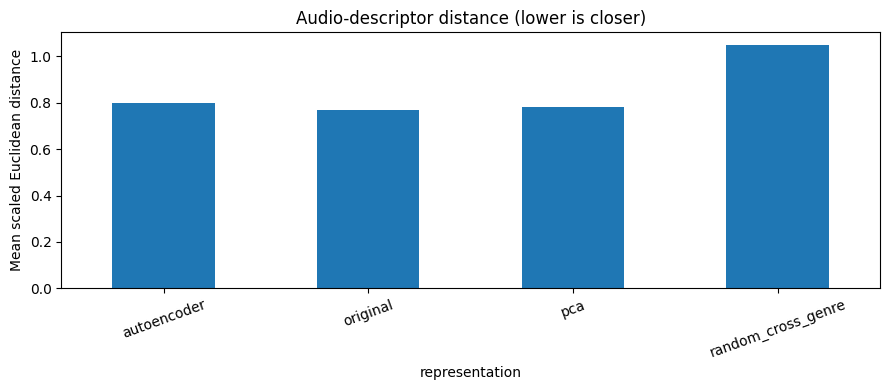

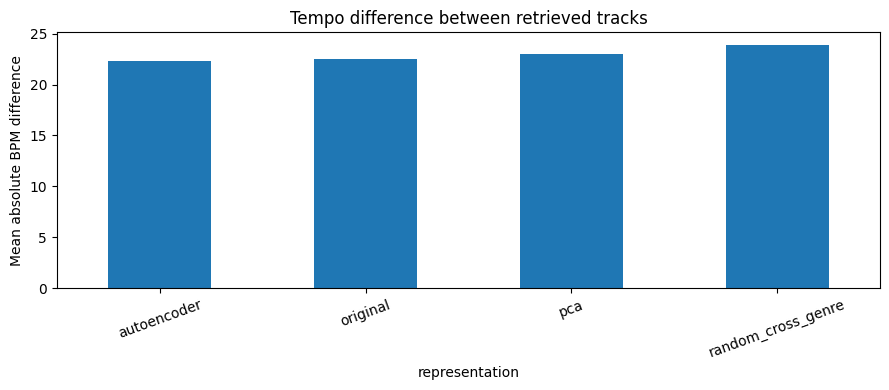

In [9]:
plot = summary.set_index('representation')
for metric, title, ylabel, filename in [
    ('mean_descriptor_distance','Audio-descriptor distance (lower is closer)',
     'Mean scaled Euclidean distance','descriptor_distance.png'),
    ('mean_tempo_difference_bpm','Tempo difference between retrieved tracks',
     'Mean absolute BPM difference','tempo_difference.png'),
]:
    ax = plot[metric].plot(kind='bar',figsize=(9,4),rot=20)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(OUT_DIR / filename,dpi=180)
    plt.show()


## 10. Inspect and listen to selected cross-genre matches

Listen to the query and retrieved track *without treating numerical descriptor closeness as proof of musical similarity*. Look for shared rhythm, instrumentation, timbre, and energy.

The audio player is optional; it reads MP3s locally. The examples CSV is useful for team listening notes.


In [10]:
examples = comparison_pairs.copy()
if genre_col:
    examples['query_genre'] = examples.query_id.map(genre_map)
    examples['neighbor_genre'] = examples.neighbor_id.map(genre_map)
    examples = examples[
        examples.query_genre.notna() &
        examples.neighbor_genre.notna() &
        (examples.query_genre != examples.neighbor_genre)
    ]
examples = examples.sort_values(['representation','descriptor_distance']).groupby(
    'representation',group_keys=False
).head(5)
examples.to_csv(OUT_DIR / 'listening_examples.csv',index=False)
display(examples[['representation','query_id','neighbor_id',
                  'descriptor_distance','tempo_diff_bpm']].head(15))

# Uncomment to play the first example:
# row = examples.iloc[0]
# print('Query:', int(row.query_id))
# display(Audio(filename=str(audio_path(row.query_id))))
# print('Neighbor:', int(row.neighbor_id))
# display(Audio(filename=str(audio_path(row.neighbor_id))))


,representation,query_id,neighbor_id,descriptor_distance,tempo_diff_bpm
17761,autoencoder,33992,121589,0.323227,5.59304
19979,autoencoder,74374,85486,0.355675,0.0
21509,autoencoder,111934,104282,0.374295,7.55551
23413,autoencoder,142536,147087,0.406472,12.952303
21508,autoencoder,111934,13596,0.422155,8.444393
1763,original,33992,121589,0.323227,5.59304
3973,original,74374,85486,0.355675,0.0
5128,original,108843,92562,0.359970,29.815204
6030,original,117885,121593,0.360685,0.0
6522,original,127189,127266,0.366392,18.563106


## 11. Interpretation and reproducibility

- **Lower descriptor differences** suggest similarity in the *measured property*, not necessarily perceptual similarity.
- The original FMA 518 features already contain audio-derived information, so this evaluation is **not independent ground truth**. Listening tests remain important.
- Results from `N_QUERIES=100` are **exploratory**. Expand to the full 800 test queries before final reporting, and report missing-audio coverage.
- The random reference is cross-genre (when genre metadata is present); compare cross-genre model pairs separately for a strict like-for-like analysis.
- Outputs are saved under `results/audio_validation/`. In Colab, `/content` is temporary: download the output files or commit small generated artifacts to your repository. In Kaggle, outputs under `/kaggle/working` can be saved as notebook outputs.
- **Next optional experiment:** train a convolutional autoencoder on log-mel spectrograms as a fourth representation, using the same retrieval protocol. This notebook intentionally focuses first on validation of your three originally proposed representations.
